# XGBoost

This notebook trains an XGBoost model to predict the death risk of leukemia patients from clinical and molecular data.


The objective is therefore twofold:
1. Evaluate the ability of XGBoost to classify patients according to their risk.
2. Analyze the quality of its probabilities before any calibration.


In [1]:
import sys
import pandas as pd
import numpy as np
import os
import importlib
from src.eval_utils import full_evaluation
from src.modeltrainer import *
import matplotlib.pyplot as plt
import glob

# Reimporter les modules pour refléter les modifications
importlib.reload(sys.modules['src.eval_utils'])
importlib.reload(sys.modules['src.modeltrainer'])

sys.path.insert(0, './src')

Loading processed data

The data has been preprocessed in previous notebooks and is now loaded in the form:
- train
- test


In [3]:
# =============================================================================
# CELLULE 1 : IMPORT DES DONNÉES
# =============================================================================


# Configuration
DATA_PATH = 'data/processed_data_imputed.xlsx'
COLS_TO_DROP = ['patient_ids', 'feat_40', 'feat_82']

# Chargement des données
print("📂 Chargement des données...")

train_data = pd.read_excel(DATA_PATH, sheet_name='train')
cal_data = pd.read_excel(DATA_PATH, sheet_name='calibration')
test_data = pd.read_excel(DATA_PATH, sheet_name='test')

# Séparation features / target
X_train = train_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_train = train_data.iloc[:, -1]


X_test = test_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_test = test_data.iloc[:, -1]

print(f"✓ Données chargées:")
print(f"   - Train: {X_train.shape[0]} lignes, {X_train.shape[1]} features")
print(f"   - Test: {X_test.shape[0]} lignes")
print(f"   - Target distribution (train): {y_train.value_counts().to_dict()}")

📂 Chargement des données...


KeyboardInterrupt: 

In [5]:
# =============================================================================
# CELLULE 2 : CHARGEMENT OU ENTRAÎNEMENT DU MODÈLE XGBoost
# =============================================================================


# Configuration
MODEL_DIR = 'models'
MODEL_TYPE = 'XGBoost'  # 'LogisticRegression', 'RandomForest', 'XGBoost'


# Initialiser le trainer
trainer = ModelML(
    x_train=X_train,
    x_test=X_test,
    y_train=y_train,
    y_test=y_test
)

# Chercher un modèle existant
existing_model = find_existing_model(MODEL_DIR, MODEL_TYPE)

if existing_model:
    print(f"📦 Modèle existant trouvé: {existing_model}")
    trainer.load_model(existing_model)
else:
    print(f"🔄 Aucun modèle {MODEL_TYPE} trouvé. Entraînement en cours...")
    
    trainer.tune_xgboost(
        param_grid={
            'n_estimators': [50, 100, 200],
            'max_depth': [3, 5, 7],
            'learning_rate': [0.01, 0.1],
            'subsample': [0.6, 0.8, 1.0]
        },
        method='random',
        n_iter=20,
        cv=5,
        scoring='roc_auc'
    )
    
    trainer.save_model()
    print(f"✓ Modèle entraîné et sauvegardé")

print(f"\n📊 Modèle actif: {trainer.model_name}")
print(f"   Paramètres: {trainer.best_params}")

🔄 Aucun modèle XGBoost trouvé. Entraînement en cours...

🔍 Recherche d'hyperparamètres (RANDOM)
   Modèle: xgboost_tuned
   Scoring: roc_auc
   CV folds:  5
   Paramètres testés: ['n_estimators', 'max_depth', 'learning_rate', 'subsample']
Fitting 5 folds for each of 20 candidates, totalling 100 fits


/usr/lib/python3.12/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/usr/lib/python3.12/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/usr/lib/python3.12/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/usr/lib/pyth


✓ Meilleurs paramètres trouvés:
   - subsample:  0.8
   - n_estimators:  200
   - max_depth:  7
   - learning_rate:  0.1
   - Best CV Score (roc_auc): 0.9912

📊 Résultats:
   - Train Accuracy: 0.9539
   - Test Accuracy:  0.6879
✓ Modèle sauvegardé: models/xgboost_tuned.pkl
✓ Paramètres sauvegardés: models/xgboost_tuned_params.json
✓ Modèle entraîné et sauvegardé

📊 Modèle actif: xgboost_tuned
   Paramètres: {'subsample': 0.8, 'n_estimators': 200, 'max_depth': 7, 'learning_rate': 0.1}



🔍 ÉVALUATION COMPLÈTE:  xgboost_tuned_test
📊 MÉTRIQUES D'ÉVALUATION

🎯 Métriques de Classification:
----------------------------------------
   Accuracy                 : 0.6879
   Balanced_Accuracy        : 0.6819
   Precision                : 0.6685
   Recall_Sensitivity       : 0.6181
   Specificity              : 0.7458
   F1_Score                 : 0.6423
   Matthews_Corr_Coef       : 0.3671
   Cohen_Kappa              : 0.3662

📈 Métriques Probabilistes:
----------------------------------------
   ROC_AUC                  : 0.7503
   PR_AUC                   : 0.7049
   Brier_Score              : 0.2139
   Log_Loss                 : 0.6439

📋 RAPPORT DE CLASSIFICATION
              precision    recall  f1-score   support

    Classe 0       0.70      0.75      0.72     31128
    Classe 1       0.67      0.62      0.64     25810

    accuracy                           0.69     56938
   macro avg       0.69      0.68      0.68     56938
weighted avg       0.69      0.69      0.69 

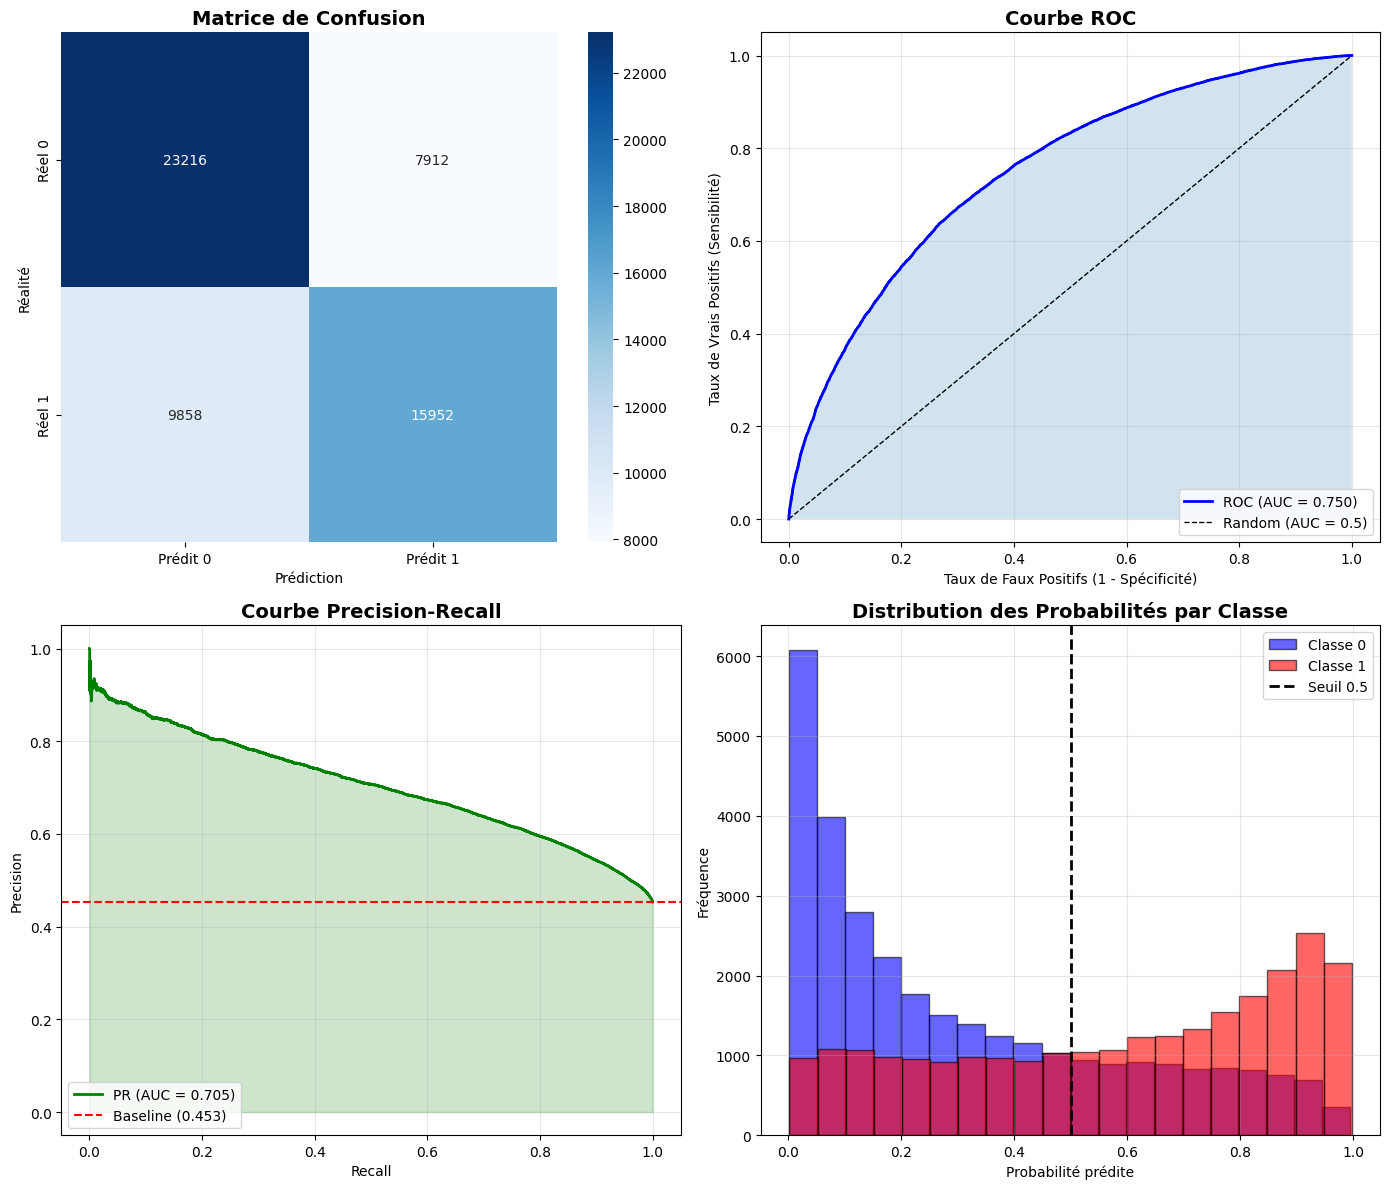

In [6]:
# =============================================================================
# CELLULE 3 : ÉVALUATION COMPLÈTE SUR LE TEST SET
# =============================================================================


y_pred_test = trainer.predict(X_test)
y_proba_test = trainer.predict_proba(X_test)[:, 1]

metrics_test = full_evaluation(
    y_true=y_test,
    y_pred=y_pred_test,
    y_proba=y_proba_test,
    model_name=f"{trainer.model_name}_test",
    save_dir='results'
)

# Afficher les plots
plt.show()

# XGBoost Results Analysis

### Model Performance
- **ROC-AUC: 0.753** — Discriminative capacity slightly lower than other models
- **Accuracy: 69.3%** — Correct but lagging performance
- **Brier Score: 0.211** — High score indicating **miscalibration** of probabilities
- **Log Loss: 0.634** — The highest, confirming the model's overconfidence


XGBoost shows a tendency toward **overconfidence** — the predicted probabilities are too extreme (close to 0 or 1) relative to the actual observed frequencies.